<a href="https://colab.research.google.com/github/phansiriphat-wi/waste_classification_project/blob/main/waste_seg.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip -q install roboflow scikit-learn seaborn

In [3]:
from roboflow import Roboflow
from getpass import getpass

api_key = getpass("Roboflow API Key: ")

rf = Roboflow(api_key=api_key)

project = rf.workspace(
    "vaishnavi8mu4s"
).project("waste-segregation-3xph4")

version = project.version(5)

dataset = version.download("folder")

print("Dataset location:", dataset.location)

Roboflow API Key: ··········
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to waste-segregation-5 in folder:: 100%|██████████| 2647/2647 [00:00<00:00, 4905.68it/s]

Dataset location: /content/waste-segregation-5


In [3]:
import os

dataset_path = dataset.location

print("Dataset:", dataset_path)

for root, dirs, files in os.walk(dataset_path):
    level = root.replace(dataset_path, "").count(os.sep)

    if level > 2:
        continue

    indent = "  " * level

    print(indent + os.path.basename(root) + "/")

    for d in dirs[:10]:
        print(indent + "  " + d + "/")

Dataset: /content/waste-segregation-5
waste-segregation-5/
  train/
  valid/
  test/
  train/
    Recyclable/
    Organic/
    Non-recyclable/
    Hazardous/
    Recyclable/
    Organic/
    Non-recyclable/
    Hazardous/
  valid/
    Recyclable/
    Organic/
    Non-recyclable/
    Hazardous/
    Recyclable/
    Organic/
    Non-recyclable/
    Hazardous/
  test/
    Recyclable/
    Organic/
    Non-recyclable/
    Hazardous/
    Recyclable/
    Organic/
    Non-recyclable/
    Hazardous/


In [4]:
import os
import pandas as pd

dataset_path = dataset.location

class_names = [
    "Hazardous",
    "Non-recyclable",
    "Organic",
    "Recyclable"
]

splits = ["train", "valid", "test"]

results = []

for split in splits:
    for class_name in class_names:
        folder = os.path.join(
            dataset_path, split, class_name
        )

        if os.path.isdir(folder):
            count = len([
                f for f in os.listdir(folder)
                if f.lower().endswith(
                    (".jpg", ".jpeg", ".png", ".webp")
                )
            ])
        else:
            count = 0
            print("Missing folder:", folder)

        results.append({
            "Split": split,
            "Class": class_name,
            "Images": count
        })

df = pd.DataFrame(results)

print(df.pivot(
    index="Class",
    columns="Split",
    values="Images"
).to_string())

print("\nTotal images:", df["Images"].sum())

print("\nImages per split:")
print(df.groupby("Split")["Images"].sum())

Split           test  train  valid
Class                             
Hazardous         65    473    130
Non-recyclable    65    445    128
Organic           67    469    132
Recyclable        66    460    130

Total images: 2630

Images per split:
Split
test      263
train    1847
valid     520
Name: Images, dtype: int64


In [5]:
split_counts = df.groupby("Split")["Images"].sum()

total = split_counts.sum()

print("Dataset Split Ratio")
print("-" * 35)

for split in ["train", "valid", "test"]:
    count = split_counts[split]
    percentage = count / total * 100

    print(
        f"{split:6s}: {count:4d} images "
        f"({percentage:.2f}%)"
    )

Dataset Split Ratio
-----------------------------------
train : 1847 images (70.23%)
valid :  520 images (19.77%)
test  :  263 images (10.00%)


In [6]:
import os
import hashlib
from collections import defaultdict

split_hashes = {}

for split in ["train", "valid", "test"]:
    hashes = set()

    for class_name in class_names:
        folder = os.path.join(
            dataset_path, split, class_name
        )

        for filename in os.listdir(folder):
            if filename.lower().endswith(
                (".jpg", ".jpeg", ".png", ".webp")
            ):
                path = os.path.join(folder, filename)

                with open(path, "rb") as f:
                    file_hash = hashlib.sha256(
                        f.read()
                    ).hexdigest()

                hashes.add(file_hash)

    split_hashes[split] = hashes

pairs = [
    ("train", "valid"),
    ("train", "test"),
    ("valid", "test")
]

for a, b in pairs:
    duplicates = len(
        split_hashes[a] & split_hashes[b]
    )
    print(f"{a} vs {b}: {duplicates} exact duplicates")

train vs valid: 0 exact duplicates
train vs test: 0 exact duplicates
valid vs test: 0 exact duplicates


In [7]:
import tensorflow as tf

IMG_SIZE = (128, 128)
BATCH_SIZE = 16
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(dataset_path, "train"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    class_names=class_names,
    shuffle=True,
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(dataset_path, "valid"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    class_names=class_names,
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(dataset_path, "test"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    class_names=class_names,
    shuffle=False
)

print("Classes:", train_ds.class_names)

Found 1847 files belonging to 4 classes.
Found 520 files belonging to 4 classes.
Found 263 files belonging to 4 classes.
Classes: ['Hazardous', 'Non-recyclable', 'Organic', 'Recyclable']


In [8]:
import tensorflow as tf
from tensorflow.keras import layers, models

tf.keras.utils.set_random_seed(42)

model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    # ปรับค่าพิกเซลจาก 0-255 เป็น 0-1
    layers.Rescaling(1./255),

    # Convolution Block 1
    layers.Conv2D(32, (3, 3),
                  activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Convolution Block 2
    layers.Conv2D(64, (3, 3),
                  activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Convolution Block 3
    layers.Conv2D(128, (3, 3),
                  activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Classification
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),

    # Output 4 classes
    layers.Dense(4, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,276 (430.77 KB)

 Trainable params: 110,276 (430.77 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
model.compile(
    optimizer=tf.keras.optimizers.RMSprop(
        learning_rate=0.0001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("CNN compiled successfully!")

CNN compiled successfully!


In [10]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=12,
        restore_best_weights=True
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=100,
    callbacks=callbacks
)

Epoch 1/100
116/116 ━━━━━━━━━━━━━━━━━━━━ 25s 129ms/step - accuracy: 0.2648 - loss: 1.3840 - val_accuracy: 0.3519 - val_loss: 1.3770
Epoch 2/100
116/116 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - accuracy: 0.3064 - loss: 1.3738 - val_accuracy: 0.3654 - val_loss: 1.3611
Epoch 3/100
116/116 ━━━━━━━━━━━━━━━━━━━━ 6s 48ms/step - accuracy: 0.3378 - loss: 1.3589 - val_accuracy: 0.3596 - val_loss: 1.3429
Epoch 4/100
116/116 ━━━━━━━━━━━━━━━━━━━━ 4s 33ms/step - accuracy: 0.3541 - loss: 1.3401 - val_accuracy: 0.3404 - val_loss: 1.3265
Epoch 5/100
116/116 ━━━━━━━━━━━━━━━━━━━━ 5s 43ms/step - accuracy: 0.3525 - loss: 1.3236 - val_accuracy: 0.3442 - val_loss: 1.3101
Epoch 6/100
116/116 ━━━━━━━━━━━━━━━━━━━━ 5s 45ms/step - accuracy: 0.3503 - loss: 1.3178 - val_accuracy: 0.3538 - val_loss: 1.3016
Epoch 7/100
116/116 ━━━━━━━━━━━━━━━━━━━━ 9s 34ms/step - accuracy: 0.3687 - loss: 1.3062 - val_accuracy: 0.3731 - val_loss: 1.2963
Epoch 8/100
116/116 ━━━━━━━━━━━━━━━━━━━━ 6s 49ms/step - accuracy: 0.3568 - loss: 1.2967 

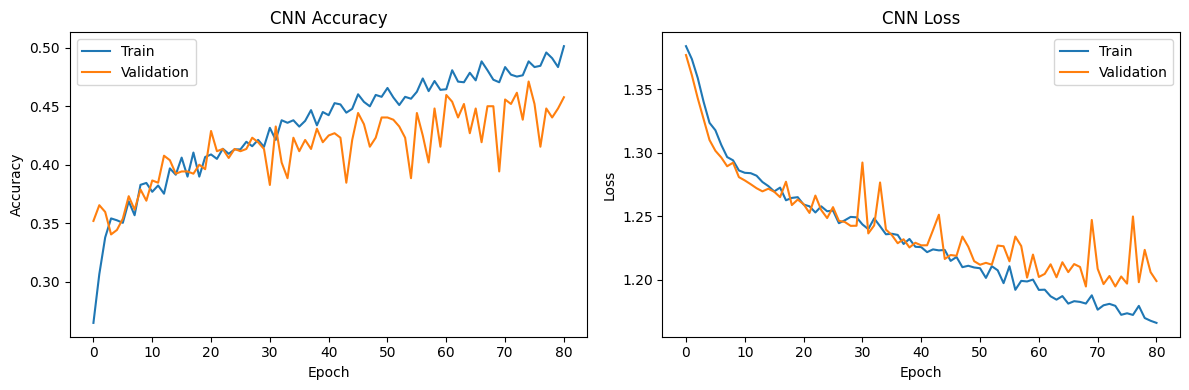

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Train")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Train")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [12]:
train_loss, train_acc = model.evaluate(
    train_ds, verbose=0
)

val_loss, val_acc = model.evaluate(
    val_ds, verbose=0
)

print("CNN Baseline Results")
print(f"Train Accuracy: {train_acc*100:.2f}%")
print(f"Validation Accuracy: {val_acc*100:.2f}%")
print(f"Validation Loss: {val_loss:.4f}")

CNN Baseline Results
Train Accuracy: 49.97%
Validation Accuracy: 45.00%
Validation Loss: 1.1947


Classification Report
                precision    recall  f1-score   support

     Hazardous     0.3913    0.4846    0.4330       130
Non-recyclable     0.4640    0.4531    0.4585       128
       Organic     0.5385    0.6364    0.5833       132
    Recyclable     0.3718    0.2231    0.2788       130

      accuracy                         0.4500       520
     macro avg     0.4414    0.4493    0.4384       520
  weighted avg     0.4417    0.4500    0.4389       520



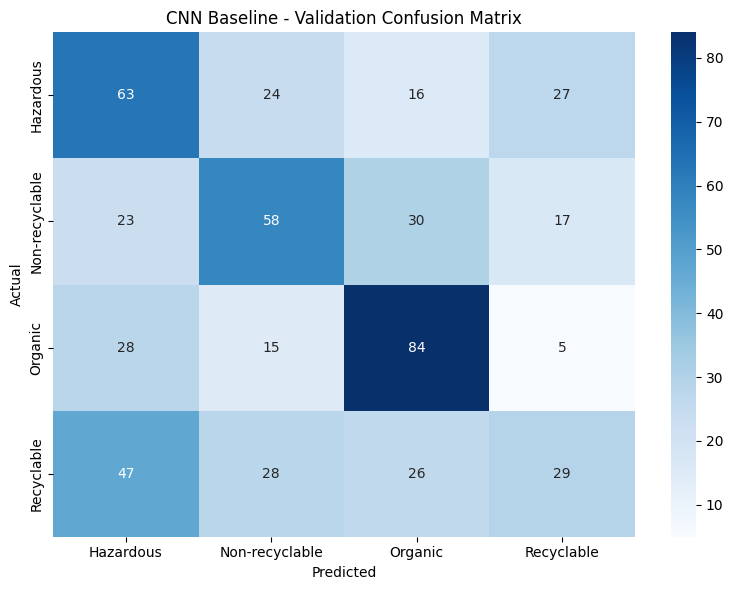

In [13]:
import numpy as np
import seaborn as sns
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score
)

y_true = np.concatenate([
    labels.numpy()
    for images, labels in val_ds
])

y_prob = model.predict(val_ds, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

print("Classification Report")
print(classification_report(
    y_true,
    y_pred,
    labels=np.arange(4),
    target_names=class_names,
    digits=4,
    zero_division=0
))

cm = confusion_matrix(
    y_true, y_pred,
    labels=np.arange(4)
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("CNN Baseline - Validation Confusion Matrix")
plt.tight_layout()
plt.show()

In [18]:
import tensorflow as tf
from tensorflow.keras import layers, models

tf.keras.utils.set_random_seed(42)

# โหลด MobileNetV2 ที่ผ่านการฝึกจาก ImageNet
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(128, 128, 3),
    include_top=False,
    weights="imagenet"
)

# ไม่ปรับ Weights ของโมเดลพื้นฐานในรอบแรก
base_model.trainable = False

model_v3 = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    # MobileNetV2 ต้องการข้อมูลภาพช่วง -1 ถึง 1
    layers.Rescaling(1./127.5, offset=-1),

    base_model,
    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(4, activation="softmax")
])

model_v3.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model_v3.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_2 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,468 (9.24 MB)

 Trainable params: 164,484 (642.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [19]:
callbacks_v3 = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True
    )
]

history_v3 = model_v3.fit(
    train_ds,
    validation_data=val_ds,
    epochs=50,
    callbacks=callbacks_v3
)

Epoch 1/50
116/116 ━━━━━━━━━━━━━━━━━━━━ 53s 285ms/step - accuracy: 0.3779 - loss: 1.5066 - val_accuracy: 0.5231 - val_loss: 1.1399
Epoch 2/50
116/116 ━━━━━━━━━━━━━━━━━━━━ 6s 50ms/step - accuracy: 0.5577 - loss: 1.0701 - val_accuracy: 0.5750 - val_loss: 1.0118
Epoch 3/50
116/116 ━━━━━━━━━━━━━━━━━━━━ 10s 44ms/step - accuracy: 0.6286 - loss: 0.9175 - val_accuracy: 0.6096 - val_loss: 0.9380
Epoch 4/50
116/116 ━━━━━━━━━━━━━━━━━━━━ 4s 37ms/step - accuracy: 0.7055 - loss: 0.7756 - val_accuracy: 0.6231 - val_loss: 0.9114
Epoch 5/50
116/116 ━━━━━━━━━━━━━━━━━━━━ 5s 34ms/step - accuracy: 0.7320 - loss: 0.7154 - val_accuracy: 0.6346 - val_loss: 0.8814
Epoch 6/50
116/116 ━━━━━━━━━━━━━━━━━━━━ 5s 47ms/step - accuracy: 0.7731 - loss: 0.6280 - val_accuracy: 0.6635 - val_loss: 0.8624
Epoch 7/50
116/116 ━━━━━━━━━━━━━━━━━━━━ 9s 38ms/step - accuracy: 0.7953 - loss: 0.5745 - val_accuracy: 0.6654 - val_loss: 0.8590
Epoch 8/50
116/116 ━━━━━━━━━━━━━━━━━━━━ 6s 48ms/step - accuracy: 0.8148 - loss: 0.5274 - val_a

In [20]:
import numpy as np
from sklearn.metrics import f1_score

train_loss_v3, train_acc_v3 = model_v3.evaluate(
    train_ds, verbose=0
)

val_loss_v3, val_acc_v3 = model_v3.evaluate(
    val_ds, verbose=0
)

y_prob_v3 = model_v3.predict(val_ds, verbose=0)
y_pred_v3 = np.argmax(y_prob_v3, axis=1)

y_true_v3 = np.concatenate([
    labels.numpy()
    for images, labels in val_ds
])

macro_f1_v3 = f1_score(
    y_true_v3,
    y_pred_v3,
    average="macro",
    zero_division=0
)

print("CNN V3 Results")
print(f"Train Accuracy: {train_acc_v3*100:.2f}%")
print(f"Validation Accuracy: {val_acc_v3*100:.2f}%")
print(f"Validation Loss: {val_loss_v3:.4f}")
print(f"Macro F1-score: {macro_f1_v3:.4f}")

CNN V3 Results
Train Accuracy: 93.07%
Validation Accuracy: 67.31%
Validation Loss: 0.8444
Macro F1-score: 0.6723


CNN V3 Classification Report
                precision    recall  f1-score   support

     Hazardous     0.6565    0.6615    0.6590       130
Non-recyclable     0.6557    0.6250    0.6400       128
       Organic     0.7101    0.7424    0.7259       132
    Recyclable     0.6667    0.6615    0.6641       130

      accuracy                         0.6731       520
     macro avg     0.6723    0.6726    0.6723       520
  weighted avg     0.6725    0.6731    0.6726       520



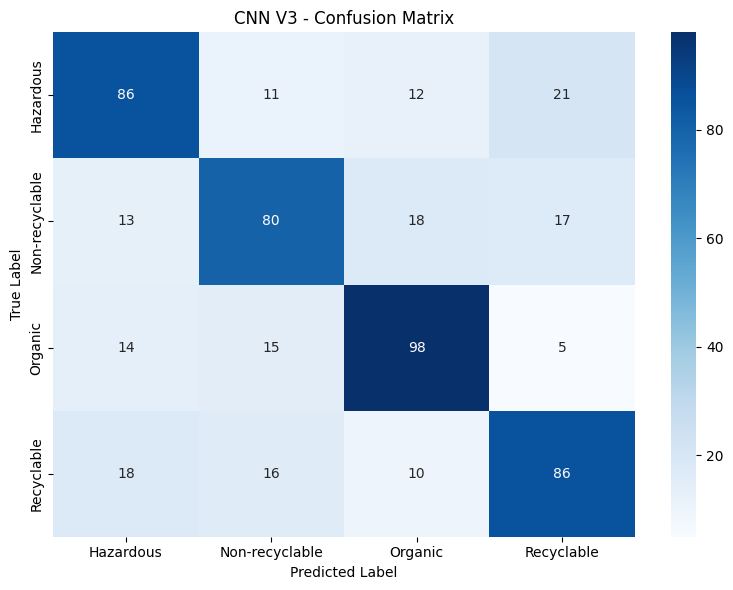

In [21]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

print("CNN V3 Classification Report")
print(
    classification_report(
        y_true_v3,
        y_pred_v3,
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

cm_v3 = confusion_matrix(y_true_v3, y_pred_v3)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm_v3,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("CNN V3 - Confusion Matrix")
plt.tight_layout()
plt.show()

In [22]:
import numpy as np
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score
)

test_loss, test_acc = model_v3.evaluate(
    test_ds, verbose=0
)

test_prob = model_v3.predict(
    test_ds, verbose=0
)

test_pred = np.argmax(test_prob, axis=1)

test_true = np.concatenate([
    labels.numpy()
    for images, labels in test_ds
])

test_macro_f1 = f1_score(
    test_true,
    test_pred,
    average="macro",
    zero_division=0
)

print("CNN V3 Final Test Results")
print(f"Test Accuracy: {test_acc*100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Macro F1-score: {test_macro_f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        test_true,
        test_pred,
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

CNN V3 Final Test Results
Test Accuracy: 63.88%
Test Loss: 0.8928
Test Macro F1-score: 0.6378

Classification Report:
                precision    recall  f1-score   support

     Hazardous     0.6034    0.5385    0.5691        65
Non-recyclable     0.5833    0.6462    0.6131        65
       Organic     0.7385    0.7164    0.7273        67
    Recyclable     0.6324    0.6515    0.6418        66

      accuracy                         0.6388       263
     macro avg     0.6394    0.6381    0.6378       263
  weighted avg     0.6401    0.6388    0.6385       263



In [23]:
model_v3.save("waste_segregation_mobilenetv2.keras")

print("CNN V3 saved successfully!")

CNN V3 saved successfully!


In [24]:
from google.colab import files

files.download("waste_segregation_mobilenetv2.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

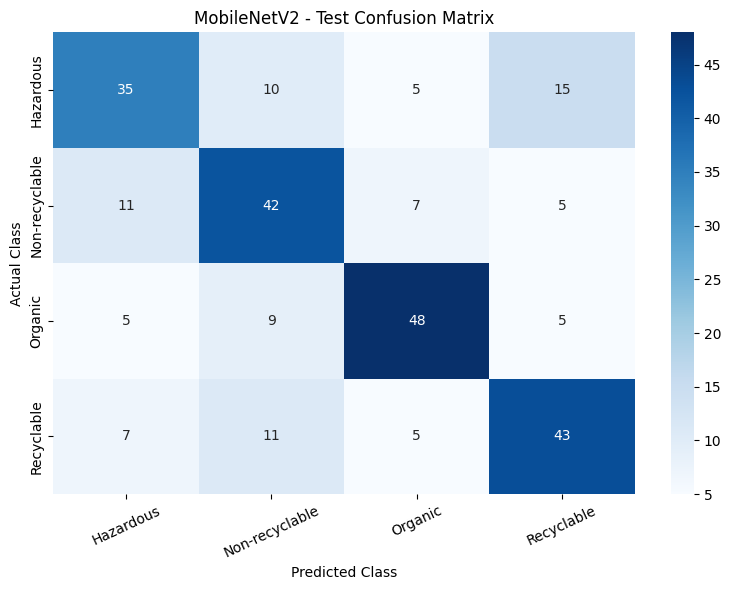

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(test_true, test_pred)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("MobileNetV2 - Test Confusion Matrix")
plt.xticks(rotation=25)
plt.tight_layout()

plt.savefig("test_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

In [26]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.metrics import confusion_matrix, classification_report

OUTPUT_DIR = "/content/research_figures"
os.makedirs(OUTPUT_DIR, exist_ok=True)

class_names = [
    "Hazardous",
    "Non-recyclable",
    "Organic",
    "Recyclable"
]

plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["font.size"] = 11

print("Output folder:", OUTPUT_DIR)

Output folder: /content/research_figures


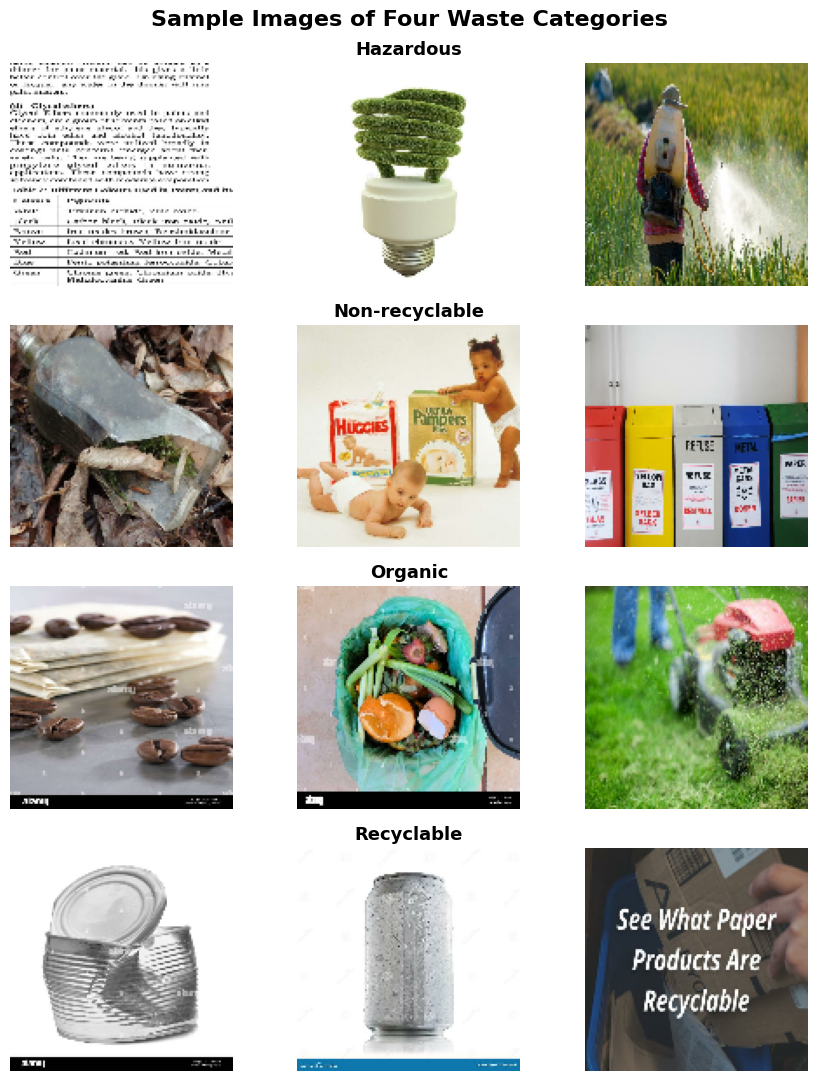

In [27]:
import matplotlib.pyplot as plt
import numpy as np
import os

fig, axes = plt.subplots(4, 3, figsize=(9, 11))

# เก็บตัวอย่างจากแต่ละประเภท
samples = {i: [] for i in range(4)}

for images, labels in train_ds.unbatch().batch(32):
    for image, label in zip(images, labels):
        label = int(label.numpy())

        if len(samples[label]) < 3:
            samples[label].append(image.numpy())

    if all(len(v) >= 3 for v in samples.values()):
        break

for i, class_name in enumerate(class_names):
    for j in range(3):
        ax = axes[i, j]

        if j < len(samples[i]):
            image = samples[i][j]
            ax.imshow(np.clip(image, 0, 255).astype("uint8"))

        ax.axis("off")

        if j == 1:
            ax.set_title(class_name, fontsize=13, fontweight="bold")

plt.suptitle(
    "Sample Images of Four Waste Categories",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/figure1_dataset_samples.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 220,554 (861.54 KB)

 Trainable params: 110,276 (430.77 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 110,278 (430.78 KB)

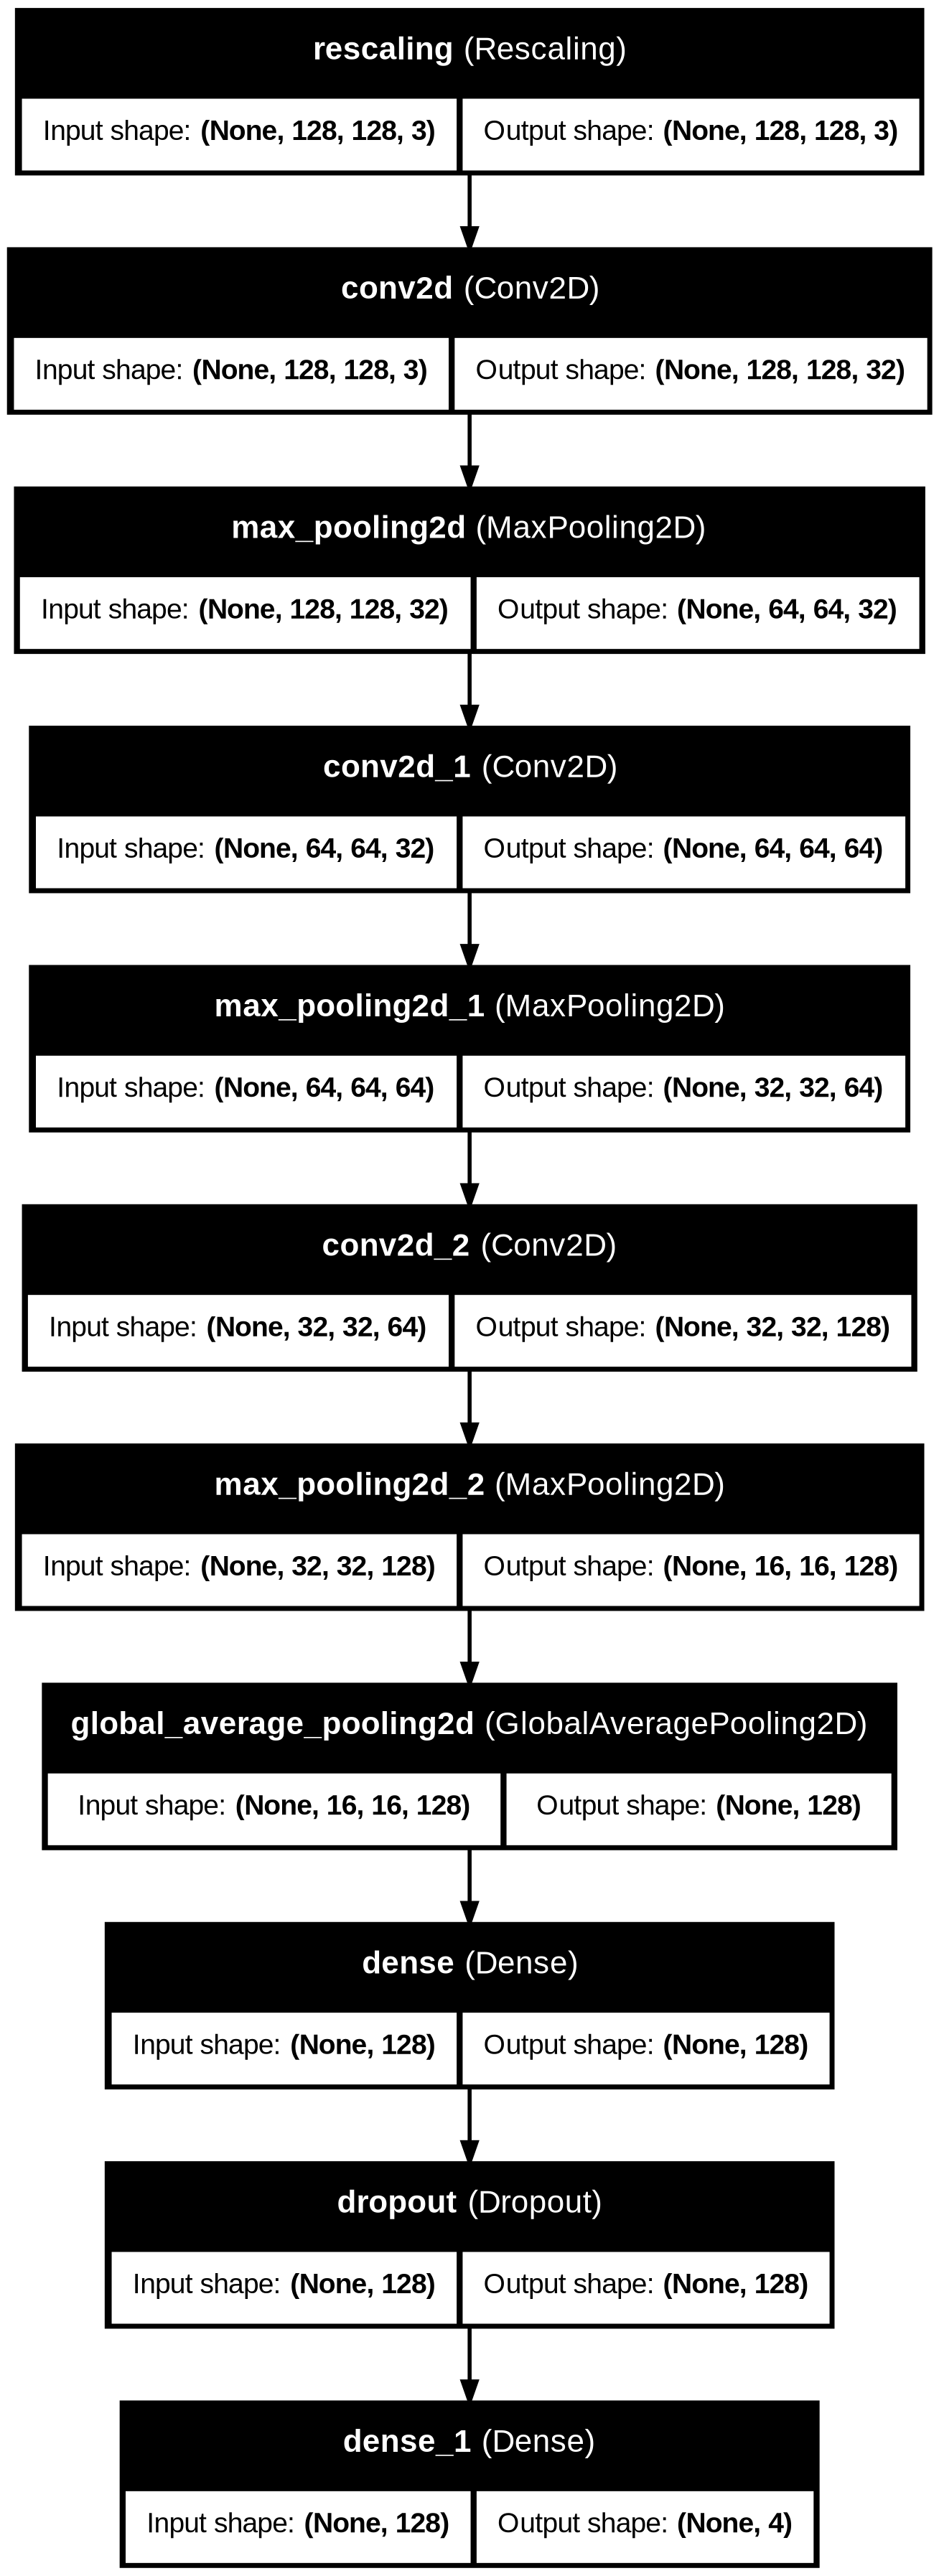

In [28]:
!pip -q install pydot
!apt-get -qq install graphviz

from tensorflow.keras.utils import plot_model
from IPython.display import Image, display

model.summary()

plot_model(
    model,
    to_file=f"{OUTPUT_DIR}/figure2_cnn_baseline.png",
    show_shapes=True,
    show_layer_names=True,
    show_layer_activations=False,
    dpi=200,
    rankdir="TB"
)

display(Image(filename=f"{OUTPUT_DIR}/figure2_cnn_baseline.png"))

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_2 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,751,438 (10.50 MB)

 Trainable params: 164,484 (642.52 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

 Optimizer params: 328,970 (1.25 MB)

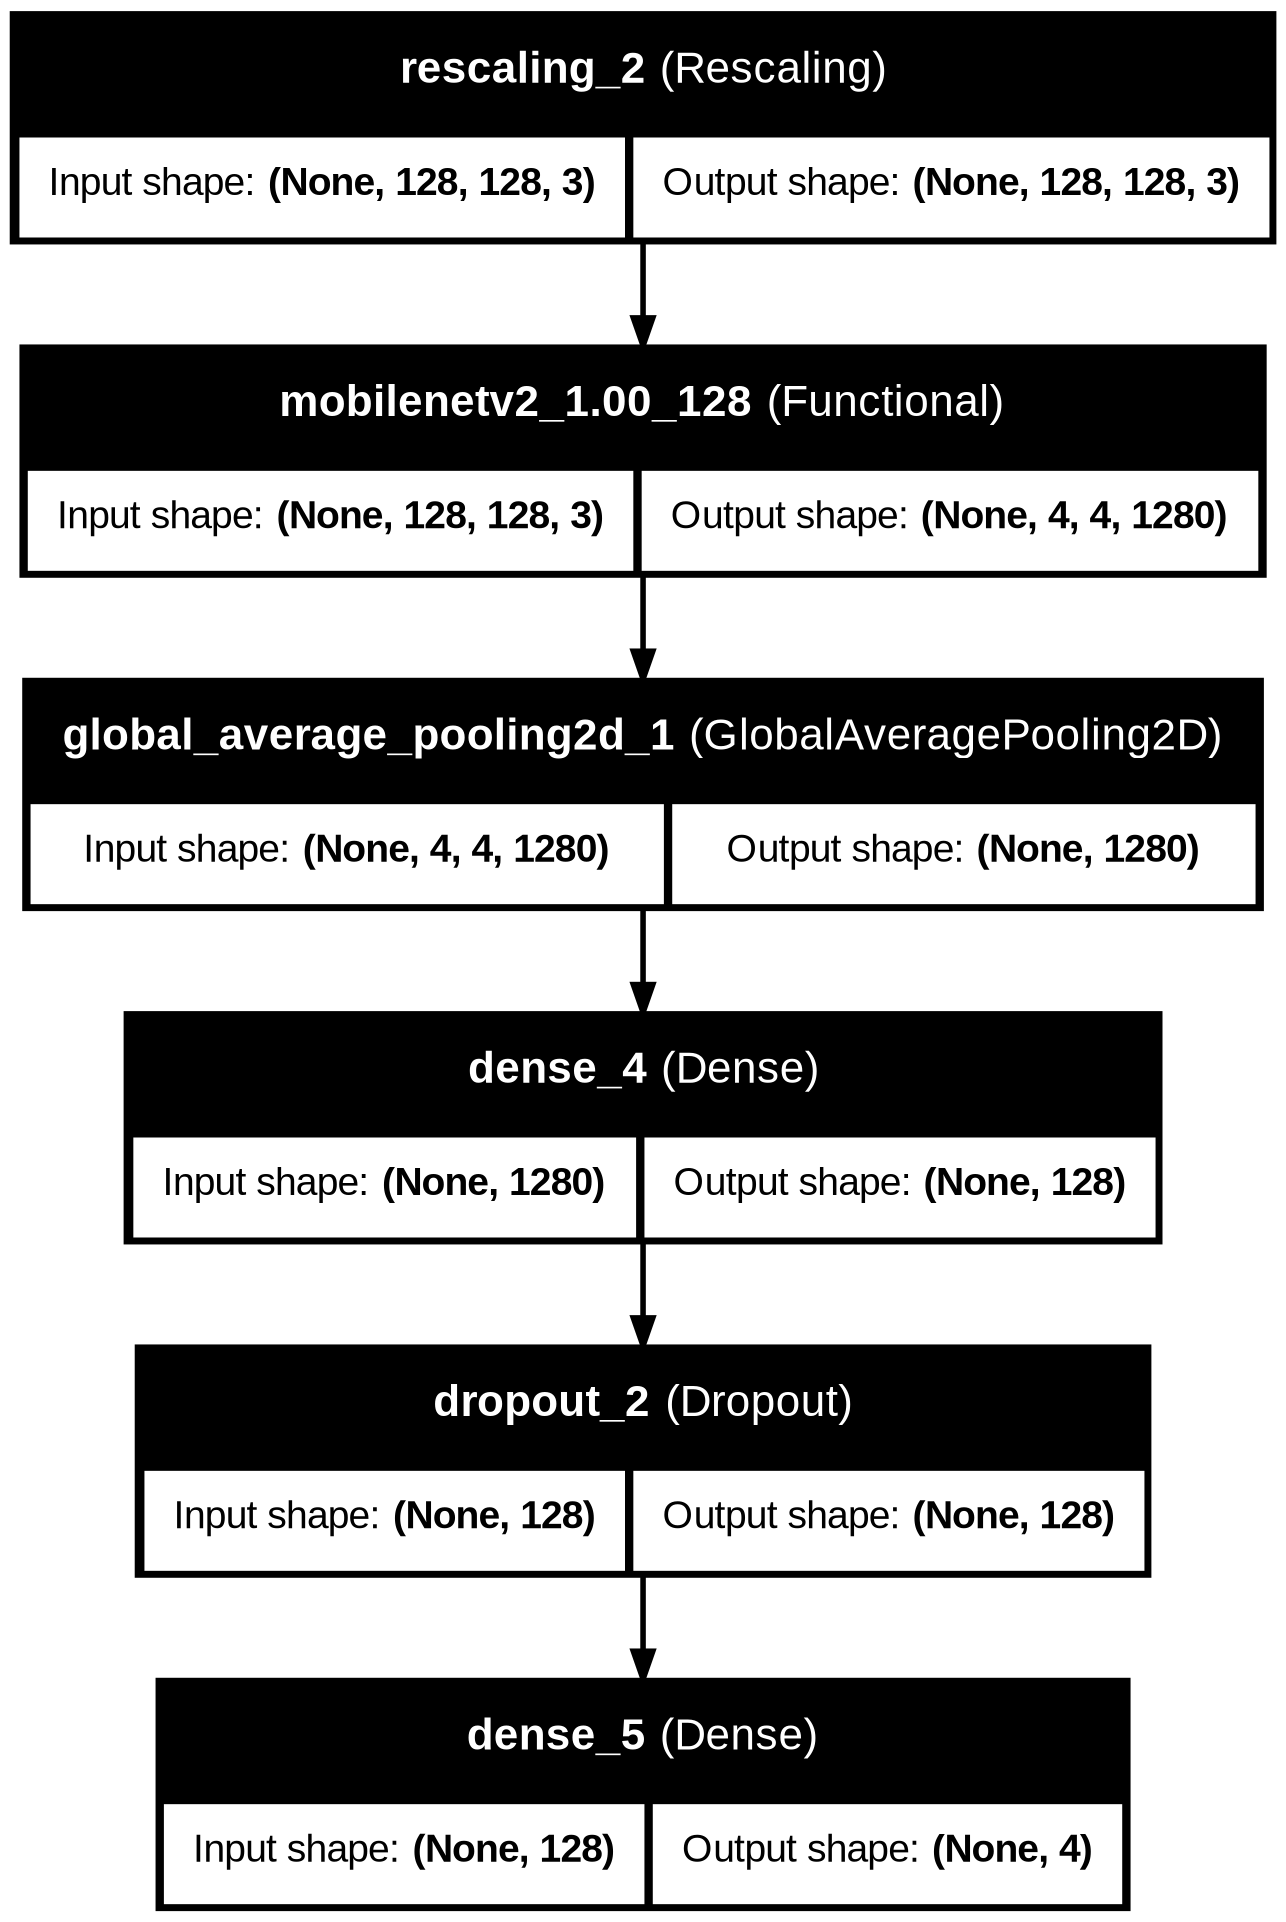

In [29]:
from tensorflow.keras.utils import plot_model
from IPython.display import Image, display

model_v3.summary()

plot_model(
    model_v3,
    to_file=f"{OUTPUT_DIR}/figure3_mobilenetv2.png",
    show_shapes=True,
    show_layer_names=True,
    show_layer_activations=False,
    expand_nested=False,
    dpi=200,
    rankdir="TB"
)

display(Image(filename=f"{OUTPUT_DIR}/figure3_mobilenetv2.png"))

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

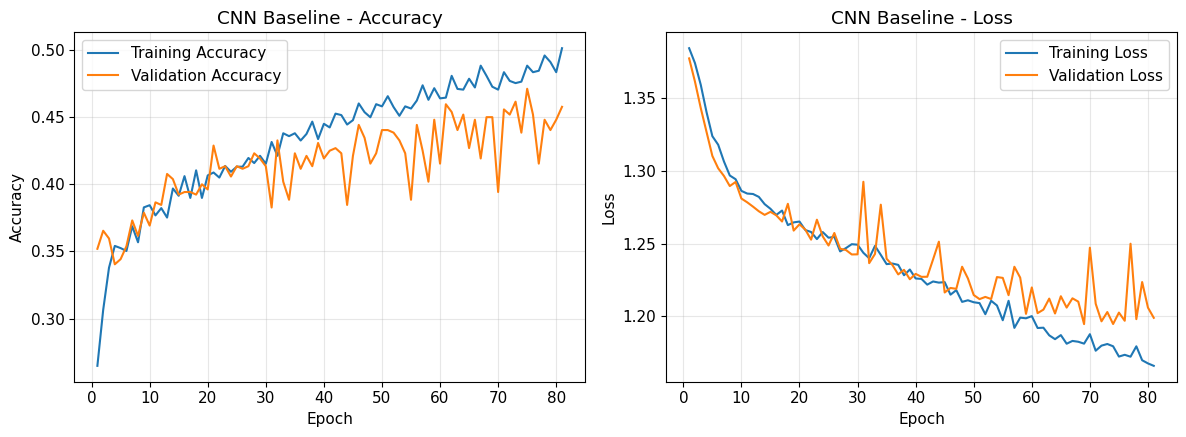

In [30]:
import matplotlib.pyplot as plt

h = history.history

epochs = range(1, len(h["accuracy"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Accuracy
axes[0].plot(
    epochs,
    h["accuracy"],
    label="Training Accuracy"
)

axes[0].plot(
    epochs,
    h["val_accuracy"],
    label="Validation Accuracy"
)

axes[0].set_title("CNN Baseline - Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Loss
axes[1].plot(
    epochs,
    h["loss"],
    label="Training Loss"
)

axes[1].plot(
    epochs,
    h["val_loss"],
    label="Validation Loss"
)

axes[1].set_title("CNN Baseline - Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/figure4_baseline_training.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

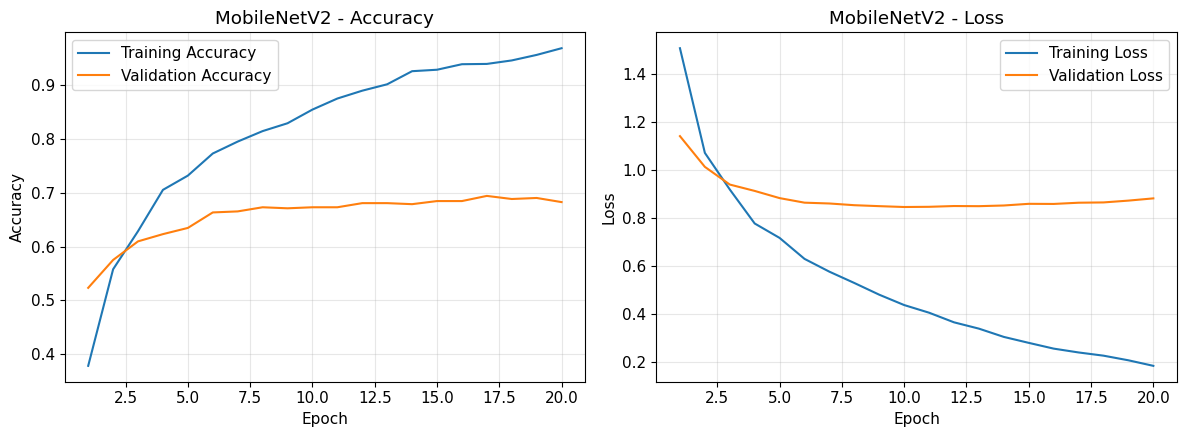

In [31]:
import matplotlib.pyplot as plt

h = history_v3.history

epochs = range(1, len(h["accuracy"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Accuracy
axes[0].plot(
    epochs,
    h["accuracy"],
    label="Training Accuracy"
)

axes[0].plot(
    epochs,
    h["val_accuracy"],
    label="Validation Accuracy"
)

axes[0].set_title("MobileNetV2 - Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Loss
axes[1].plot(
    epochs,
    h["loss"],
    label="Training Loss"
)

axes[1].plot(
    epochs,
    h["val_loss"],
    label="Validation Loss"
)

axes[1].set_title("MobileNetV2 - Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/figure5_mobilenetv2_training.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

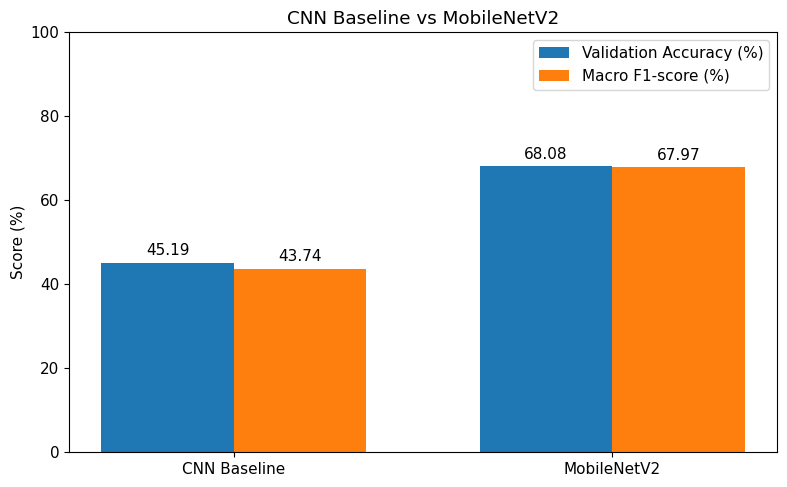

In [32]:
import matplotlib.pyplot as plt
import numpy as np

models = ["CNN Baseline", "MobileNetV2"]

val_accuracy = [45.19, 68.08]
macro_f1 = [0.4374, 0.6797]

x = np.arange(len(models))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))

bars1 = ax.bar(
    x - width/2,
    val_accuracy,
    width,
    label="Validation Accuracy (%)"
)

bars2 = ax.bar(
    x + width/2,
    np.array(macro_f1) * 100,
    width,
    label="Macro F1-score (%)"
)

ax.set_title("CNN Baseline vs MobileNetV2")
ax.set_ylabel("Score (%)")
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.set_ylim(0, 100)
ax.legend()

ax.bar_label(bars1, fmt="%.2f", padding=3)
ax.bar_label(bars2, fmt="%.2f", padding=3)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/figure6_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

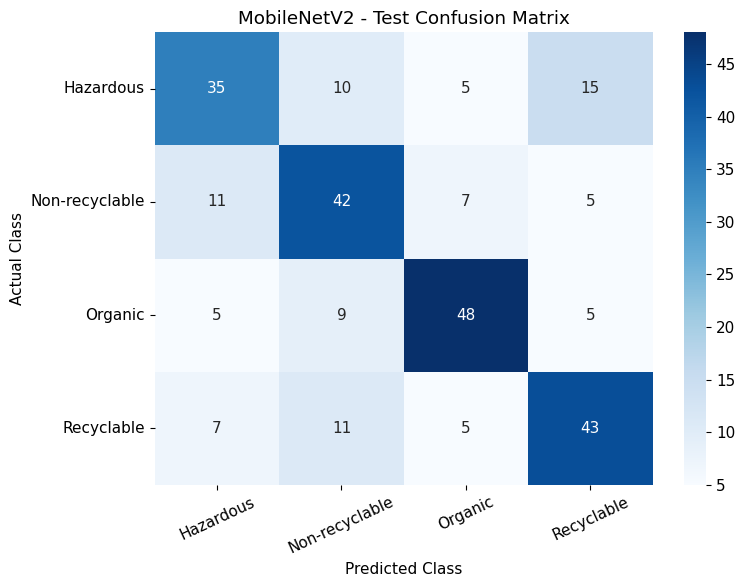

                precision    recall  f1-score   support

     Hazardous     0.6034    0.5385    0.5691        65
Non-recyclable     0.5833    0.6462    0.6131        65
       Organic     0.7385    0.7164    0.7273        67
    Recyclable     0.6324    0.6515    0.6418        66

      accuracy                         0.6388       263
     macro avg     0.6394    0.6381    0.6378       263
  weighted avg     0.6401    0.6388    0.6385       263



In [33]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix, classification_report

test_true = []
test_pred = []

for images, labels in test_ds:
    predictions = model_v3.predict(images, verbose=0)

    predicted_classes = np.argmax(predictions, axis=1)

    test_true.extend(labels.numpy())
    test_pred.extend(predicted_classes)

test_true = np.array(test_true)
test_pred = np.array(test_pred)

cm = confusion_matrix(
    test_true,
    test_pred,
    labels=range(4)
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("MobileNetV2 - Test Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(rotation=25)
plt.yticks(rotation=0)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/figure7_test_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    classification_report(
        test_true,
        test_pred,
        target_names=class_names,
        digits=4
    )
)

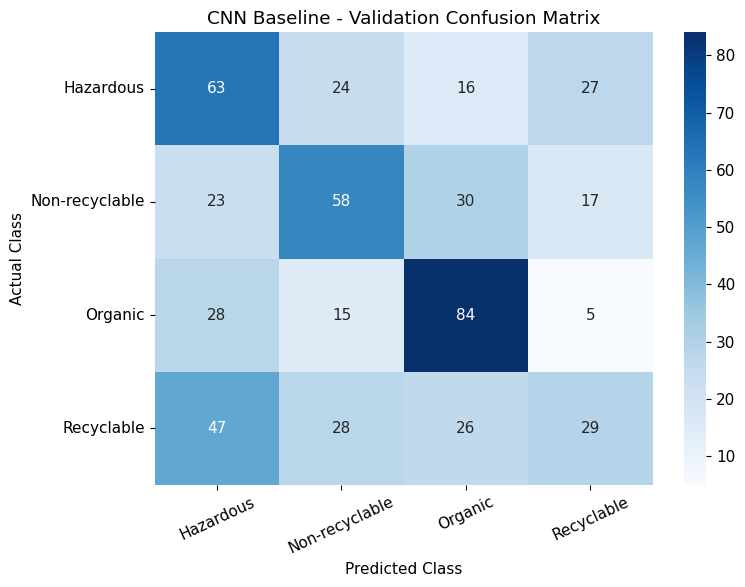

In [34]:
val_true = []
val_pred = []

for images, labels in val_ds:
    predictions = model.predict(images, verbose=0)

    val_true.extend(labels.numpy())
    val_pred.extend(np.argmax(predictions, axis=1))

cm_baseline = confusion_matrix(
    val_true,
    val_pred,
    labels=range(4)
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_baseline,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("CNN Baseline - Validation Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(rotation=25)
plt.yticks(rotation=0)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/figure8_baseline_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [35]:
import shutil
from google.colab import files

zip_path = shutil.make_archive(
    "/content/research_figures",
    "zip",
    OUTPUT_DIR
)

print("Created:", zip_path)

files.download(zip_path)

Created: /content/research_figures.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>